# Metric Stat Analysis – PPP Radar Evaluation

Loads pre-exported HDF5 evaluation files (`rank00.h5` – `rank03.h5`) produced by
the metric evaluation pipeline and provides first-look visualisation of
`img`, `pred_lambda`, and `gt_support` per sample.

Each h5 file organises samples as:
```
sample_XXXXXX/
    img          (H, W, 3)  uint8
    pred_lambda  (H, W)     float32
    gt_support   (H, W)     float32
```

## 1 · Import Required Libraries

In [1]:
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation

plt.rcParams["figure.figsize"] = (18, 5)
plt.rcParams["image.cmap"] = "hot"

## 2 · Configuration & Path Setup

In [ ]:

# ---------------------------------------------------------------------------
# Paths – one entry per model run
# ---------------------------------------------------------------------------

H5_DIRS = {
    "test_gen_data_meric_1500_13606074": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test"
    ),
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608_LR_load_model40000": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
}


# Select which model to analyse for the browser / per-sample cells
# ACTIVE_MODEL = "test_gen_data_meric_13600264"
ACTIVE_MODEL = "test_gen_data_meric_13600264"

H5_DIR = H5_DIRS[ACTIVE_MODEL]
assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

# ---------------------------------------------------------------------------
# Display parameters
# ---------------------------------------------------------------------------

# Radius (pixels) used to dilate each GT point for visibility.
# Increase to make GT dots larger in the output image.
GT_DILATION_RADIUS = 1

# ---------------------------------------------------------------------------
# Collect h5 files
# ---------------------------------------------------------------------------

h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"\nFound {len(h5_files)} h5 file(s):")
for p in h5_files:
    print(" ", p)

print(f"\nGT_DILATION_RADIUS = {GT_DILATION_RADIUS}  (display only)")


Active model : test_gen_data_meric_13600264
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test

Found 4 h5 file(s):
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank03.h5

GT_DILATION_RADIUS = 1  (display only)


## 3 · H5 Helper – List & Load Samples

In [3]:
def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) tuples across all rank files,
    sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from an h5 file.

    Returns a dict with:
      img          – (H, W, 3) uint8
      pred_lambda  – (H, W) float32   [lambda(x), i.e. predicted intensity]
      gt_support   – (H, W) float32   [binary point support {0,1}]
      ppp          – derived diagnostics dict
    """
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]           # (H, W, 3) uint8
        pred_lambda = grp["pred_lambda"][:]   # (H, W)    float32
        gt_support  = grp["gt_support"][:]    # (H, W)    float32

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count       = int(gt_support.sum())

    return {
        "img":         img,
        "pred_lambda": pred_lambda,
        "gt_support":  gt_support,
        "ppp": {
            "H":              H,
            "W":              W,
            "img_area":       H * W,
            "expected_count": expected_count,
            "gt_count":       gt_count,
            "count_error":    expected_count - gt_count,
        },
        "meta": {
            "h5_file":    os.path.basename(h5_path),
            "sample_key": sample_key,
        },
    }


# Build global sample index
all_samples = list_h5_samples(h5_files)
print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(f"  {os.path.basename(entry[0])} / {entry[1]}")

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


## 4 · PPP Sampling Methods

In [4]:
def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) per pixel (mass per pixel, non-negative).
    pixel_area : float
        Kept for API compatibility, not used.
    rng : np.random.Generator

    Returns
    -------
    points_xy  : (N, 2) array  – accepted points in image coords (x, y)
    N          : int
    lambda_max : float
    N_prop     : int           – number of proposals before thinning
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",
    rng: np.random.Generator | None = None,
):
    """
    Block/Bernoulli approximation of a PPP.

    For each block A:
        Λ_A = sum_A λ * pixel_area
        Activate with p_A = 1 - exp(-Λ_A)
    If active, place exactly one point in A.

    Parameters
    ----------
    lambda_grid : (H, W) array  – intensity mass per pixel
    block_size  : int           – side length of each block in pixels
    pixel_area  : float         – set to 1.0 when lambda_grid is already mass per pixel
    placement   : "weighted" | "uniform"

    Returns
    -------
    points_xy : (N, 2) array
    stats     : dict
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    if lam.ndim != 2:
        raise ValueError("lambda_grid must be 2D.")
    if not np.all(np.isfinite(lam)):
        raise ValueError("lambda_grid contains NaN/Inf.")
    if np.any(lam < 0):
        raise ValueError("lambda_grid contains negative values.")
    if placement not in {"weighted", "uniform"}:
        raise ValueError("placement must be 'weighted' or 'uniform'")

    bs = int(block_size)
    H, W = lam.shape
    nby = (H + bs - 1) // bs
    nbx = (W + bs - 1) // bs
    num_blocks = nby * nbx

    Hp, Wp = nby * bs, nbx * bs
    if Hp != H or Wp != W:
        lam_pad = np.zeros((Hp, Wp), dtype=np.float64)
        lam_pad[:H, :W] = lam
    else:
        lam_pad = lam

    lam_blocks = lam_pad.reshape(nby, bs, nbx, bs).transpose(0, 2, 1, 3)
    block_sums = lam_blocks.sum(axis=(2, 3)) * pixel_area  # (nby, nbx)

    p_active = 1.0 - np.exp(-block_sums)
    expected_blocks_active = float(p_active.sum())

    active_mask = rng.random(size=(nby, nbx)) < p_active
    active_by, active_bx = np.nonzero(active_mask)
    num_active = active_by.size

    if num_active == 0:
        return np.zeros((0, 2), dtype=np.float64), dict(
            block_size=bs, placement=placement,
            num_blocks=num_blocks, num_active_blocks=0,
            expected_active_blocks=expected_blocks_active, num_points=0,
        )

    points_xy = np.empty((num_active, 2), dtype=np.float64)
    x0s = active_bx * bs
    y0s = active_by * bs
    wBs = np.minimum(bs, W - x0s)
    hBs = np.minimum(bs, H - y0s)

    if placement == "uniform":
        points_xy[:, 0] = x0s + rng.random(num_active) * wBs
        points_xy[:, 1] = y0s + rng.random(num_active) * hBs
    else:
        for i, (by, bx, x0, y0, wB, hB) in enumerate(
            zip(active_by, active_bx, x0s, y0s, wBs, hBs)
        ):
            block = lam[y0:y0 + hB, x0:x0 + wB]
            s = block.sum()
            if s <= 0:
                points_xy[i, 0] = x0 + rng.random() * wB
                points_xy[i, 1] = y0 + rng.random() * hB
                continue
            probs = block.ravel() / s
            idx = rng.choice(probs.size, p=probs)
            py, px = divmod(idx, wB)
            points_xy[i, 0] = x0 + px + rng.random()
            points_xy[i, 1] = y0 + py + rng.random()

    return points_xy, dict(
        block_size=bs, placement=placement,
        num_blocks=num_blocks, num_active_blocks=int(num_active),
        expected_active_blocks=expected_blocks_active, num_points=int(num_active),
    )

print("Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli")


Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli


## 4 · Load & Display First Sample: Image, Lambda, GT

Sample : rank00.h5  /  sample_000000
Shape  : img=(544, 1792, 3)  pred_lambda=(544, 1792)  gt_support=(544, 1792)
PPP    : E[N]=106.85  GT=67  err=+39.85


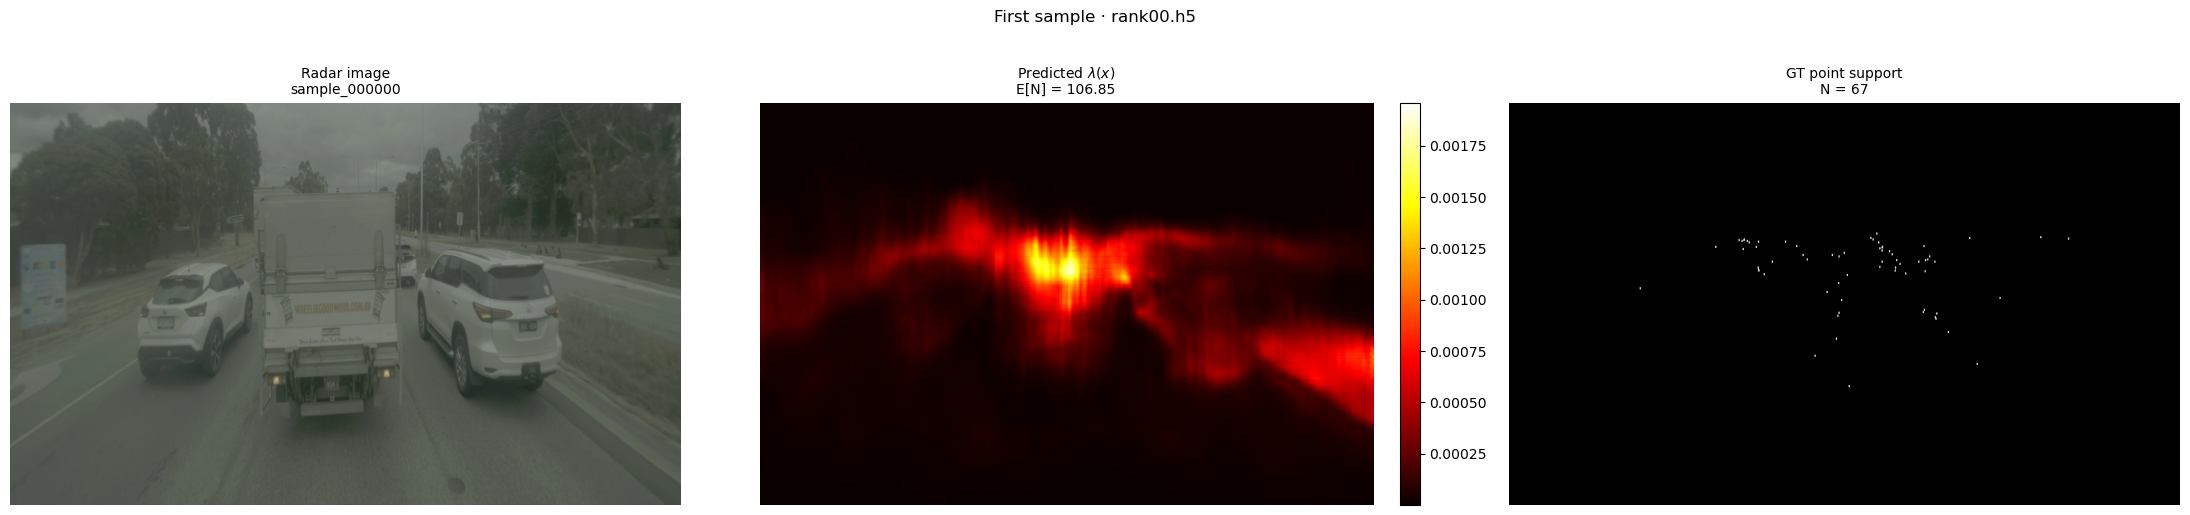

In [5]:
# Load first sample
h5_path_0, key_0 = all_samples[0]
sample = load_h5_sample(h5_path_0, key_0)

img         = sample["img"]
pred_lambda = sample["pred_lambda"]
gt_support  = sample["gt_support"]   # original – untouched
ppp         = sample["ppp"]
meta        = sample["meta"]

print(f"Sample : {meta['h5_file']}  /  {meta['sample_key']}")
print(f"Shape  : img={img.shape}  pred_lambda={pred_lambda.shape}  gt_support={gt_support.shape}")
print(f"PPP    : E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}  err={ppp['count_error']:+.2f}")

# GT point coordinates (row=y, col=x)
gt_ys, gt_xs = np.where(gt_support > 0)

# --- Side-by-side plot ---
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

ax = axes[0]
ax.imshow(img, aspect="auto")
ax.set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
ax.axis("off")

ax = axes[1]
im = ax.imshow(pred_lambda, cmap="hot", aspect="auto")
ax.set_title(
    r"Predicted $\lambda(x)$"
    f"\nE[N] = {ppp['expected_count']:.2f}",
    fontsize=10,
)
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax = axes[2]
_struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
_gt_vis = binary_dilation(gt_support > 0, structure=_struct)
gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
gt_rgb[_gt_vis] = 255
ax.imshow(gt_rgb, aspect="auto")
ax.set_title(
    f"GT point support\nN = {ppp['gt_count']}",
    fontsize=10,
)
ax.axis("off")

plt.suptitle(f"First sample · {meta['h5_file']}", fontsize=12, y=1.02)


plt.tight_layout()
plt.show()

## 5 · Interactive Sample Browser

Use the slider to step through samples. Click **"Add to selection"** to mark the current sample. The selected keys are collected in `selected_samples` (printed in the cell below).

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# ── persistent selection list ────────────────────────────────────────────────
selected_samples = []   # list of (h5_file, sample_key)

# ── widgets ──────────────────────────────────────────────────────────────────
n = len(all_samples)

slider = widgets.IntSlider(
    value=0, min=0, max=n - 1, step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="600px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆  Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

lbl_status = widgets.Label(value=f"0 / {n} selected")

plot_out   = widgets.Output()
select_out = widgets.Output()


def _update_btn_label(idx):
    """Reflect whether the current sample is already in the selection."""
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)
    btn_add.value       = entry in selected_samples
    btn_add.description = "★  In selection" if btn_add.value else "☆  Add to selection"
    btn_add.button_style = "success" if btn_add.value else ""


def _render(idx):
    h5_path, key = all_samples[idx]
    sample = load_h5_sample(h5_path, key)

    img         = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support  = sample["gt_support"]
    ppp         = sample["ppp"]
    meta        = sample["meta"]

    gt_ys, gt_xs = np.where(gt_support > 0)

    with plot_out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(22, 5))

        axes[0].imshow(img, aspect="auto")
        axes[0].set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
        axes[0].axis("off")

        im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
        axes[1].set_title(
            r"Predicted $\lambda(x)$" + f"\nE[N] = {ppp['expected_count']:.2f}",
            fontsize=10,
        )
        axes[1].axis("off")
        plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

        _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
        _gt_vis = binary_dilation(gt_support > 0, structure=_struct)
        _gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
        _gt_rgb[_gt_vis] = 255
        axes[2].imshow(_gt_rgb, aspect="auto")
        axes[2].set_title(
            f"GT support\nN = {ppp['gt_count']}",
            fontsize=10,
        )
        axes[2].axis("off")

        plt.suptitle(
            f"[{idx + 1}/{n}]  {meta['h5_file']}  ·  {meta['sample_key']}"
            f"   |   E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}"
            f"  err={ppp['count_error']:+.2f}",
            fontsize=11, y=1.02,
        )
        plt.tight_layout()
        plt.show()


def _refresh_selection_output():
    with select_out:
        clear_output(wait=True)
        if selected_samples:
            print(f"Selected ({len(selected_samples)}):")
            for h5f, k in selected_samples:
                print(f"  {h5f}  /  {k}")
        else:
            print("No samples selected yet.")


def on_slider_change(change):
    _update_btn_label(change["new"])
    _render(change["new"])


def on_toggle_change(change):
    idx = slider.value
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)

    if change["new"]:                          # toggled ON → add
        if entry not in selected_samples:
            selected_samples.append(entry)
        btn_add.description  = "★  In selection"
        btn_add.button_style = "success"
    else:                                      # toggled OFF → remove
        if entry in selected_samples:
            selected_samples.remove(entry)
        btn_add.description  = "☆  Add to selection"
        btn_add.button_style = ""

    lbl_status.value = f"{len(selected_samples)} / {n} selected"
    _refresh_selection_output()


slider.observe(on_slider_change, names="value")
btn_add.observe(on_toggle_change, names="value")

# ── initial render ────────────────────────────────────────────────────────────
_update_btn_label(0)
_render(0)
_refresh_selection_output()

# ── layout ────────────────────────────────────────────────────────────────────
controls = widgets.HBox([slider, btn_add, lbl_status])

display(widgets.VBox([controls, plot_out, select_out]))
# ── layout ────────────────────────────────────────────────────────────────────controls = widgets.HBox([slider, btn_add, lbl_status])display(widgets.VBox([controls, plot_out, select_out]))


In [8]:
# ── Print final selection (run this cell after browsing) ─────────────────────
print(f"selected_samples = {selected_samples!r}")


selected_samples = [('rank02.h5', 'sample_000005')]


## Analysis: Visual Inspection Variance Sampling

Takes the **first sample** from `selected_samples` and draws **two independent point clouds**
from the predicted λ heatmap — one per sampling method — displayed side by side with the GT.

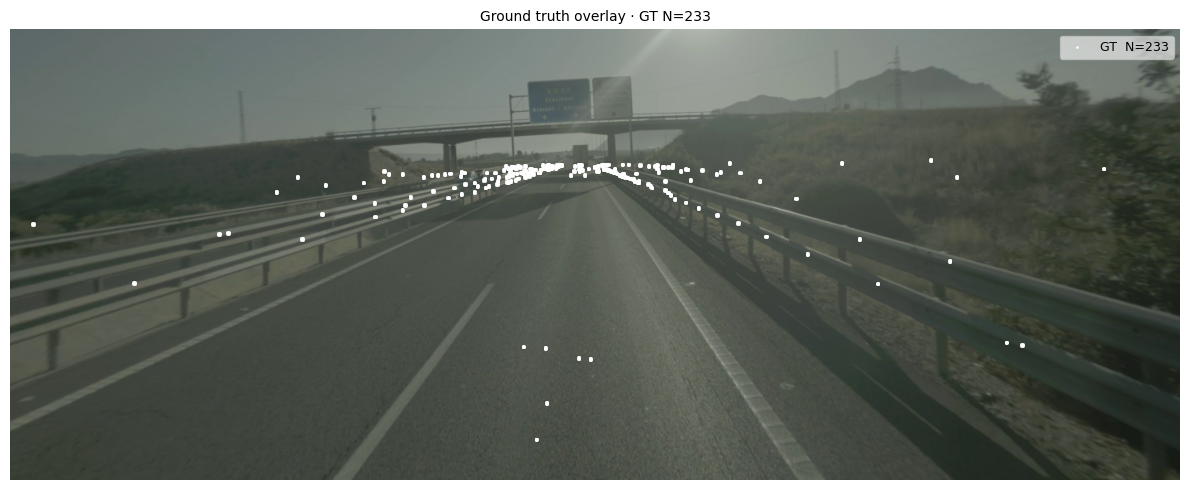

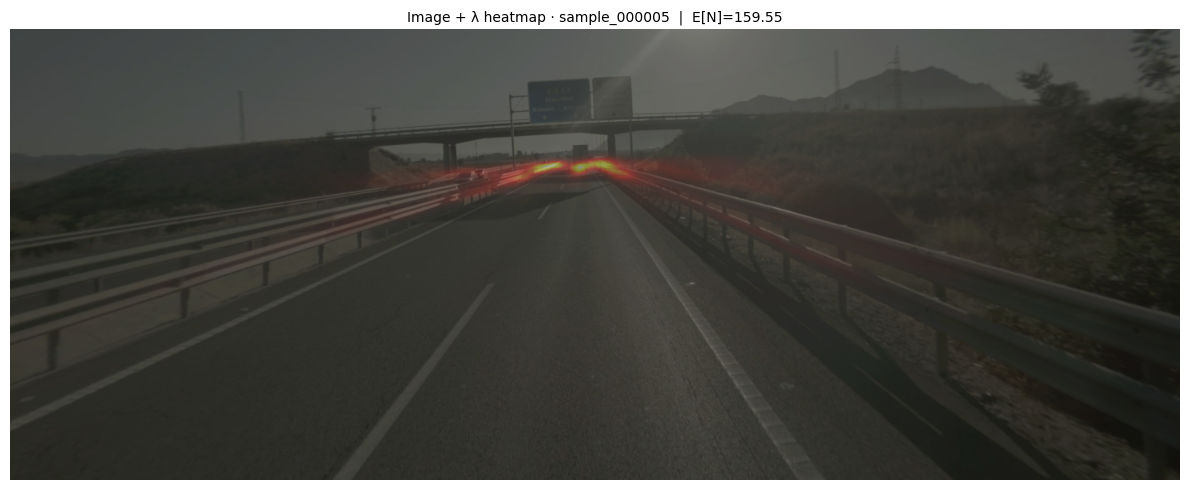

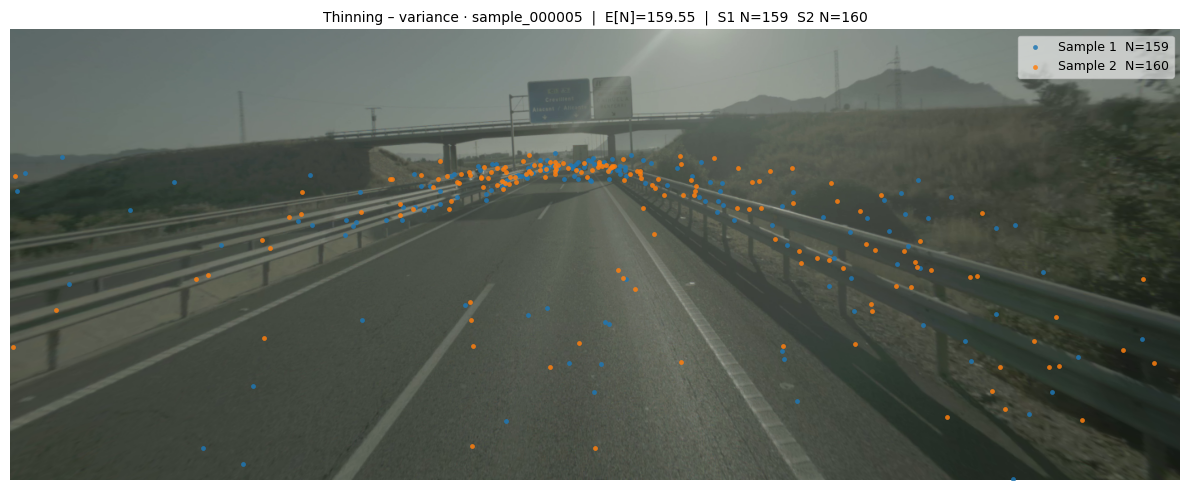

In [9]:
assert selected_samples, "No samples selected – browse and add at least one above."

# Load first selected sample
_h5_file, _key = selected_samples[0]
_h5_path = next(
    p for (p, k) in all_samples
    if os.path.basename(p) == _h5_file and k == _key
)
_sample = load_h5_sample(_h5_path, _key)

_img         = _sample["img"]
_pred_lambda = _sample["pred_lambda"]
_gt_support  = _sample["gt_support"]
_ppp         = _sample["ppp"]

H_img, W_img = _pred_lambda.shape
DOT_SIZE    = 12   # pt² for sampled points
GT_DOT_SIZE = 4    # pt² for GT points (smaller)
N_SAMPLES   = 2    # ← change this to draw more independent samples

_COLORS = plt.cm.tab10.colors  # up to 10 distinct colours

# ── N independent thinning draws ─────────────────────────────────────────────
_thin_samples = [
    sample_ppp_by_thinning(_pred_lambda, rng=np.random.default_rng(seed=i))
    for i in range(N_SAMPLES)
]

# ── shared GT coords ──────────────────────────────────────────────────────────
_struct  = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), bool)
_gt_ys, _gt_xs = np.where(binary_dilation(_gt_support > 0, structure=_struct))

# ── Plot 1: image with GT overlaid ────────────────────────────────────────────
fig_gt, ax_gt = plt.subplots(1, 1, figsize=(12, 5))
ax_gt.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
if _gt_ys.size > 0:
    ax_gt.scatter(_gt_xs, _gt_ys,
                  s=GT_DOT_SIZE, c="white", linewidths=0, alpha=0.9,
                  label=f"GT  N={_ppp['gt_count']}")
ax_gt.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_gt.axis("off")
ax_gt.set_title(f"Ground truth overlay · GT N={_ppp['gt_count']}", fontsize=10)
plt.tight_layout()
plt.show()

# ── Plot 2: image + faint lambda overlay ──────────────────────────────────────
fig_lam, ax_lam = plt.subplots(1, 1, figsize=(12, 5))
ax_lam.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
ax_lam.imshow(_pred_lambda, cmap="hot", aspect="auto",
              extent=[0, W_img, H_img, 0], alpha=0.35)
ax_lam.axis("off")
ax_lam.set_title(
    f"Image + λ heatmap · {_key}  |  E[N]={_ppp['expected_count']:.2f}",
    fontsize=10,
)
plt.tight_layout()
plt.show()

# ── Plot 3: N thinning samples overlaid on image ──────────────────────────────
fig_thin, ax_thin = plt.subplots(1, 1, figsize=(12, 5))
ax_thin.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
counts_str = []
for i, (pts, n, _, _) in enumerate(_thin_samples):
    if n > 0:
        ax_thin.scatter(pts[:, 0], pts[:, 1],
                        s=DOT_SIZE, c=[_COLORS[i % len(_COLORS)]],
                        linewidths=0, alpha=0.85,
                        label=f"Sample {i+1}  N={n}")
    counts_str.append(f"S{i+1} N={n}")
ax_thin.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_thin.axis("off")
ax_thin.set_title(
    f"Thinning – variance · {_key}  |  E[N]={_ppp['expected_count']:.2f}  |  "
    + "  ".join(counts_str),
    fontsize=10,
)
plt.tight_layout()
plt.show()


In [10]:

# ── Promote selected-sample variables for use in all downstream cells ─────────
# The interactive browser loaded the selection into _pred_lambda / _gt_support.
# Here we alias them to the unprefixed names so the projection cells below
# always operate on the interactively selected sample, not the first one loaded.
pred_lambda = _pred_lambda
gt_support  = _gt_support
img         = _img
ppp         = _ppp
H, W        = pred_lambda.shape
D           = H * W

print(f"Active sample : {_h5_file}  /  {_key}")
print(f"Shape         : pred_lambda={pred_lambda.shape}  "
      f"gt_support={gt_support.shape}")
print(f"PPP           : E[N]={ppp['expected_count']:.2f}  "
      f"GT={ppp['gt_count']}  err={ppp['count_error']:+.2f}")


Active sample : rank02.h5  /  sample_000005
Shape         : pred_lambda=(544, 1792)  gt_support=(544, 1792)
PPP           : E[N]=159.55  GT=233  err=-73.45


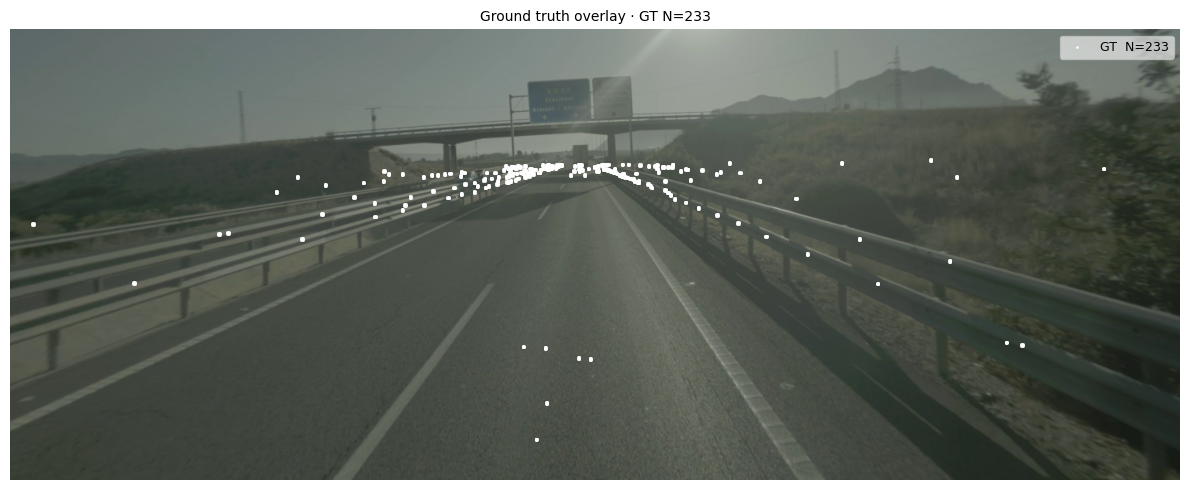

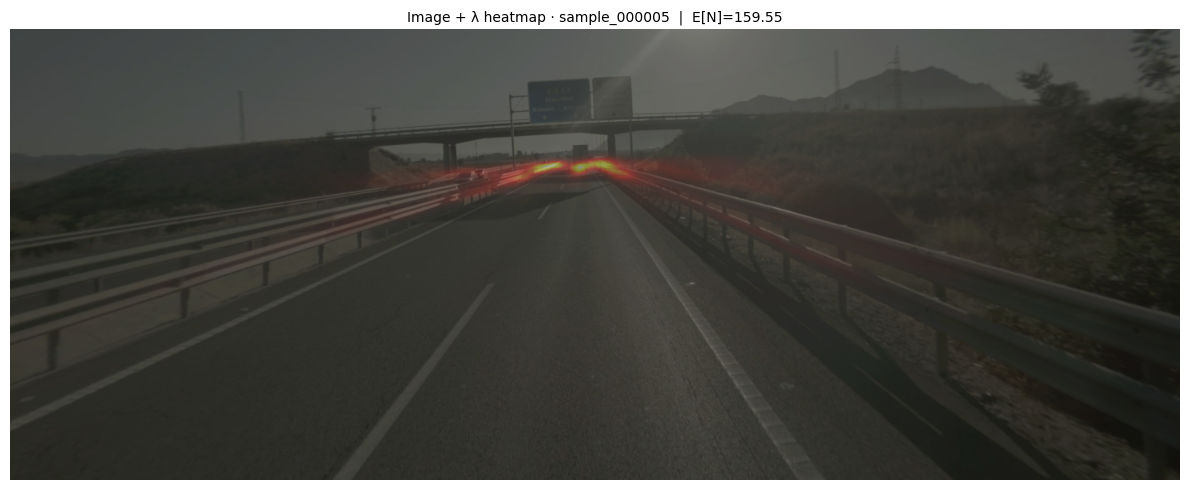

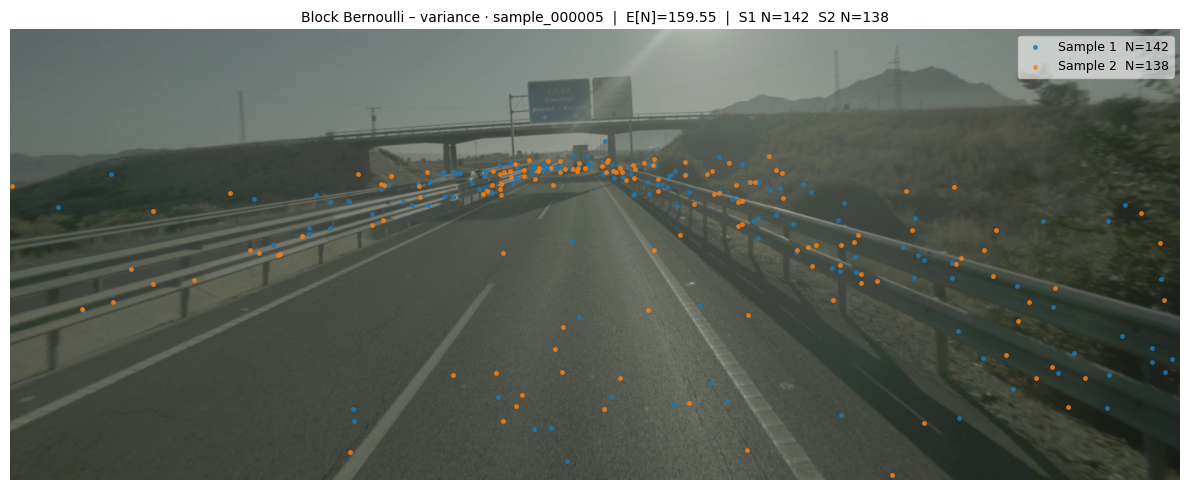

In [11]:
# ── N independent Block Bernoulli draws ──────────────────────────────────────
_bb_samples = [
    sample_points_block_bernoulli(
        _pred_lambda, block_size=8, placement="weighted",
        rng=np.random.default_rng(seed=i)
    )
    for i in range(N_SAMPLES)
]

# ── Plot 1: image with GT overlaid ────────────────────────────────────────────
fig_gt2, ax_gt2 = plt.subplots(1, 1, figsize=(12, 5))
ax_gt2.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
if _gt_ys.size > 0:
    ax_gt2.scatter(_gt_xs, _gt_ys,
                   s=GT_DOT_SIZE, c="white", linewidths=0, alpha=0.9,
                   label=f"GT  N={_ppp['gt_count']}")
ax_gt2.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_gt2.axis("off")
ax_gt2.set_title(f"Ground truth overlay · GT N={_ppp['gt_count']}", fontsize=10)
plt.tight_layout()
plt.show()

# ── Plot 2: image + faint lambda overlay ──────────────────────────────────────
fig_lam2, ax_lam2 = plt.subplots(1, 1, figsize=(12, 5))
ax_lam2.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
ax_lam2.imshow(_pred_lambda, cmap="hot", aspect="auto",
               extent=[0, W_img, H_img, 0], alpha=0.35)
ax_lam2.axis("off")
ax_lam2.set_title(
    f"Image + λ heatmap · {_key}  |  E[N]={_ppp['expected_count']:.2f}",
    fontsize=10,
)
plt.tight_layout()
plt.show()

# ── Plot 3: N block Bernoulli samples overlaid on image ───────────────────────
fig_bb, ax_bb = plt.subplots(1, 1, figsize=(12, 5))
ax_bb.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
counts_str = []
for i, (pts, stats) in enumerate(_bb_samples):
    n = stats["num_points"]
    if n > 0:
        ax_bb.scatter(pts[:, 0], pts[:, 1],
                      s=DOT_SIZE, c=[_COLORS[i % len(_COLORS)]],
                      linewidths=0, alpha=0.85,
                      label=f"Sample {i+1}  N={n}")
    counts_str.append(f"S{i+1} N={n}")
ax_bb.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_bb.axis("off")
ax_bb.set_title(
    f"Block Bernoulli – variance · {_key}  |  E[N]={_ppp['expected_count']:.2f}  |  "
    + "  ".join(counts_str),
    fontsize=10,
)
plt.tight_layout()
plt.show()


In [12]:
print(f"dtype      : {gt_support.dtype}")
print(f"shape      : {gt_support.shape}")
print(f"unique vals: {np.unique(gt_support)}")
print(f"min/max    : {gt_support.min():.4f} / {gt_support.max():.4f}")
print(f"nonzero px : {(gt_support > 0).sum()}")


dtype      : float32
shape      : (544, 1792)
unique vals: [0. 1.]
min/max    : 0.0000 / 1.0000
nonzero px : 233


In [13]:

# ── 5.1  Low-level helpers ───────────────────────────────────────────────────

def points_to_binary_grid(points_xy: np.ndarray, H: int, W: int) -> np.ndarray:
    """
    Convert a point cloud to a binary occupancy grid.

    Parameters
    ----------
    points_xy : (N, 2) float array
        Point coordinates in image space (x = column, y = row).
        May be empty (shape (0, 2)).
    H, W : int
        Grid dimensions.

    Returns
    -------
    grid : (H, W) float64 array with values in {0.0, 1.0}.
        Multiple points falling on the same pixel are collapsed to 1.
    """
    grid = np.zeros((H, W), dtype=np.float64)
    if points_xy.shape[0] > 0:
        xi = np.clip(points_xy[:, 0].astype(int), 0, W - 1)
        yi = np.clip(points_xy[:, 1].astype(int), 0, H - 1)
        grid[yi, xi] = 1.0
    return grid


def random_unit_vectors(
    n_projections: int,
    D: int,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """
    Sample `n_projections` unit vectors uniformly on the unit sphere S^{D-1}.

    Method
    ------
    Draw each component i.i.d. from N(0,1) and normalise to unit length.
    This works because the standard multivariate Gaussian N(0, I_D) is
    *spherically symmetric*: the distribution of z/||z|| is uniform on S^{D-1}
    regardless of D. This is the standard and theoretically exact method.

    Numerical stability
    -------------------
    After normalisation each row has ||v||_2 = 1 to machine precision.
    The probability of drawing an all-zero vector is zero for continuous
    distributions; the guard below exists only as a safety net for extreme D.

    Parameters
    ----------
    n_projections : int
    D             : int – dimensionality (= H * W, or the active subset size)
    rng           : np.random.Generator

    Returns
    -------
    vecs : (n_projections, D) float64 array, each row has ||v||_2 == 1.
    """
    if rng is None:
        rng = np.random.default_rng()
    # i.i.d. Gaussian draws → spherically symmetric distribution
    vecs = rng.standard_normal((n_projections, D))           # (P, D)
    norms = np.linalg.norm(vecs, axis=1, keepdims=True)      # (P, 1)
    # Guard: practically impossible, but defensively replace zero norms
    zero_rows = (norms[:, 0] == 0.0)
    if zero_rows.any():
        # Resample bad rows (iterative, but will terminate in expected O(1) steps)
        while zero_rows.any():
            vecs[zero_rows] = rng.standard_normal((zero_rows.sum(), D))
            norms[zero_rows] = np.linalg.norm(vecs[zero_rows], axis=1, keepdims=True)
            zero_rows = (norms[:, 0] == 0.0)
    return vecs / norms                                       # (P, D)  unit vectors


def project_samples(
    samples_flat: np.ndarray,
    projection_vectors: np.ndarray,
) -> np.ndarray:
    """
    Project every sample onto every projection vector via dot product.

    Parameters
    ----------
    samples_flat       : (n_samples, D) float array
        Each row is a flattened binary occupancy map.
    projection_vectors : (n_projections, D) float array
        Each row is a unit vector.

    Returns
    -------
    projections : (n_samples, n_projections) float array
        projections[i, k] = <samples_flat[i], projection_vectors[k]>
    """
    return samples_flat @ projection_vectors.T              # (n, P)


def gt_quantile_per_projection(
    gt_proj: np.ndarray,
    sample_proj: np.ndarray,
) -> np.ndarray:
    """
    For each projection direction, compute the empirical quantile of the GT
    scalar projection among the scalar projections of the generated samples.

    Parameters
    ----------
    gt_proj     : (n_projections,) float array
        Scalar projection value of the single GT map.
    sample_proj : (n_samples, n_projections) float array
        Scalar projection values for each generated sample and direction.

    Returns
    -------
    quantiles : (n_projections,) float array in [0, 1]
        quantiles[k] = fraction of generated samples whose projection
        onto direction k is <= the GT projection onto direction k.
    """
    return (sample_proj <= gt_proj[np.newaxis, :]).mean(axis=0)  # (P,)


print("Helpers loaded: points_to_binary_grid, random_unit_vectors, "
      "project_samples, gt_quantile_per_projection")


Helpers loaded: points_to_binary_grid, random_unit_vectors, project_samples, gt_quantile_per_projection


In [14]:

# ── 5.2  Main evaluation function ────────────────────────────────────────────

def evaluate_projections(
    pred_lambda: np.ndarray,
    gt_support: np.ndarray,
    *,
    n_samples: int = 200,
    n_projections: int = 500,
    sampling_fn=None,
    rng: np.random.Generator | None = None,
) -> dict:
    """
    Projection-based evaluation of a predicted intensity map against a GT
    binary occupancy map.

    Computational trick
    -------------------
    Before drawing projection vectors, the function computes the **active
    pixel mask** – the set of pixels that are non-zero in at least one of:
    the GT map, or any of the `n_samples` generated binary maps.

    Pixels that are zero everywhere contribute nothing to any dot product
    (since every x_i = 0 in those coordinates), so they can be discarded.
    Projection vectors are then drawn as unit vectors in R^{D_active} rather
    than R^{H*W}, so their full norm budget is spent on informative dimensions.
    This speeds up projection and avoids diluting directions across dead pixels.

    Parameters
    ----------
    pred_lambda   : (H, W) float array
        Predicted intensity heatmap (lambda per pixel, non-negative).
    gt_support    : (H, W) array
        Binary ground-truth occupancy map with values in {0, 1}.
    n_samples     : int
        Number of binary occupancy maps to sample from `pred_lambda`.
    n_projections : int
        Number of random projection directions in R^{D_active}.
    sampling_fn   : callable(lam, rng) -> (points_xy, stats)
        Function that draws one point-cloud sample from `pred_lambda`.
        Defaults to block-Bernoulli with block_size=8, placement="weighted".
    rng           : np.random.Generator
        Master RNG; child seeds are derived from it so results are
        fully reproducible when a seeded generator is supplied.

    Returns
    -------
    result : dict with keys
        quantiles          (n_projections,)            – empirical quantile of GT
        gt_projections     (n_projections,)            – GT scalar projections
        sample_projections (n_samples, n_projections)  – sample scalar projections
        projection_vectors (n_projections, D_active)   – unit vectors used (reduced space)
        active_mask        (D,) bool                   – mask of active pixels (flat)
        n_samples, n_projections, H, W, D, D_active    int
    """
    if rng is None:
        rng = np.random.default_rng()

    H, W = pred_lambda.shape
    D = H * W

    # ── default sampler ──────────────────────────────────────────────────────
    if sampling_fn is None:
        def sampling_fn(lam, child_rng):
            pts, stats = sample_points_block_bernoulli(
                lam, block_size=8, placement="weighted", rng=child_rng
            )
            return pts, stats

    # ── Step 1: generate n_samples binary occupancy maps (full resolution) ───
    child_seeds = rng.integers(0, 2**32, size=n_samples)
    sampled_flat = np.empty((n_samples, D), dtype=np.float64)
    for i, seed in enumerate(child_seeds):
        pts, _ = sampling_fn(pred_lambda, np.random.default_rng(int(seed)))
        sampled_flat[i] = points_to_binary_grid(pts, H, W).ravel()

    # ── Step 2: compute active pixel mask ─────────────────────────────────────
    # A pixel is "active" if at least one of (GT, any sample) is non-zero.
    # Dead pixels can never contribute to any projection dot-product, so
    # we safely discard them before drawing projection vectors.
    gt_flat = gt_support.astype(np.float64).ravel()          # (D,)
    active_mask = (gt_flat > 0) | (sampled_flat.any(axis=0)) # (D,) bool
    D_active = int(active_mask.sum())

    print(f"  Active pixels: {D_active:,} / {D:,}  "
          f"({100 * D_active / D:.2f}% of full space)")

    # Slice both GT and samples to active pixels
    gt_active      = gt_flat[active_mask][np.newaxis, :]     # (1, D_active)
    sampled_active = sampled_flat[:, active_mask]            # (n, D_active)

    # ── Step 3: draw unit vectors in R^{D_active} (NOT R^{H*W}) ─────────────
    # Because we sample in the reduced space, each projection vector has
    # ||v||=1 with ALL norm budget on informative (potentially non-zero) dims.
    proj_vecs = random_unit_vectors(n_projections, D_active, rng=rng)  # (P, D_active)

    # ── Step 4: project GT and generated samples ──────────────────────────────
    gt_proj   = project_samples(gt_active, proj_vecs)[0]    # (P,)
    samp_proj = project_samples(sampled_active, proj_vecs)  # (n, P)

    # ── Step 5: empirical quantile of GT per projection ───────────────────────
    quantiles = gt_quantile_per_projection(gt_proj, samp_proj)  # (P,)

    return dict(
        quantiles          = quantiles,
        gt_projections     = gt_proj,
        sample_projections = samp_proj,
        projection_vectors = proj_vecs,
        active_mask        = active_mask,
        n_samples          = n_samples,
        n_projections      = n_projections,
        H=H, W=W, D=D, D_active=D_active,
    )

print("evaluate_projections loaded (with active-pixel reduction).")


evaluate_projections loaded (with active-pixel reduction).


### 5.3 · Single-projection CDF demo

Draw one random projection direction, project all generated samples onto it to form an empirical CDF, then mark where the GT lands on that CDF.

In [27]:

# ── Sampling function wrappers ────────────────────────────────────────────────
# Change ACTIVE_SAMPLING_FN to switch the sampler used in all downstream cells.

def _thinning_fn(lam, rng):
    pts, _, _, _ = sample_ppp_by_thinning(lam, rng=rng)
    return pts, {}

def _bb_fn(lam, rng):
    pts, stats = sample_points_block_bernoulli(
        lam, block_size=8, placement="weighted", rng=rng
    )
    return pts, stats

ACTIVE_SAMPLING_FN = _thinning_fn   # ← change here to switch everywhere

print(f"Active sampling fn : {ACTIVE_SAMPLING_FN.__name__}")


Active sampling fn : _thinning_fn


Active pixels: 25,435 / 974,848  (2.61%)
GT projection value : 0.0821
GT quantile         : 0.840  (GT is above 84.0% of samples along this direction)


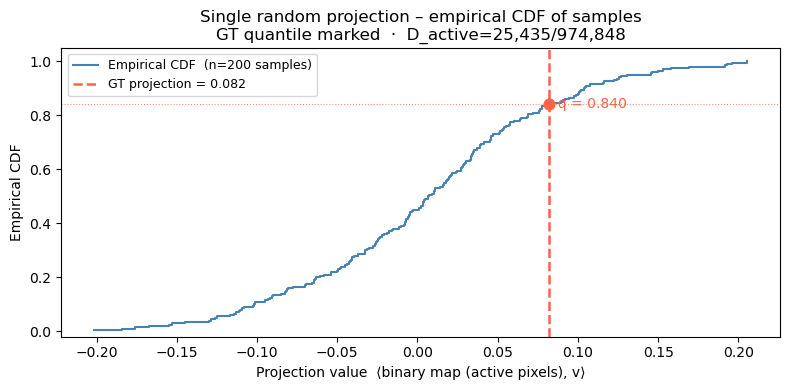

In [28]:

# ── Parameters ───────────────────────────────────────────────────────────────
N_SAMP_EVAL   = 200   # number of binary samples drawn from pred_lambda
PROJ_RNG_SEED = 0     # set to None for a different draw each run

rng = np.random.default_rng(PROJ_RNG_SEED)

H, W = pred_lambda.shape
D    = H * W

# ── Step 1: generate N binary samples (needed to build the active mask) ───────
child_seeds_demo = rng.integers(0, 2**32, size=N_SAMP_EVAL)
demo_sampled_flat = np.empty((N_SAMP_EVAL, D), dtype=np.float64)
for i, seed in enumerate(child_seeds_demo):
    pts, _ = ACTIVE_SAMPLING_FN(pred_lambda, np.random.default_rng(int(seed)))
    demo_sampled_flat[i] = points_to_binary_grid(pts, H, W).ravel()

# ── Step 2: active-pixel mask ─────────────────────────────────────────────────
gt_flat_demo   = gt_support.astype(np.float64).ravel()              # (D,)
active_mask_demo = (gt_flat_demo > 0) | demo_sampled_flat.any(axis=0)  # (D,) bool
D_active_demo    = int(active_mask_demo.sum())
print(f"Active pixels: {D_active_demo:,} / {D:,}  ({100*D_active_demo/D:.2f}%)")

gt_active_demo      = gt_flat_demo[active_mask_demo]                # (D_active,)
sampled_active_demo = demo_sampled_flat[:, active_mask_demo]        # (N, D_active)

# ── Step 3: one random unit projection vector in R^{D_active} ────────────────
# Normalised Gaussian ≡ uniform on S^{D_active - 1} (exact, any dimension).
v = random_unit_vectors(1, D_active_demo, rng=rng)[0]              # (D_active,)

# ── Step 4: project samples and GT in the reduced space ──────────────────────
sample_projs = sampled_active_demo @ v    # (N,)
gt_proj      = gt_active_demo @ v         # scalar

# ── Step 5: quantile of GT among samples ─────────────────────────────────────
gt_quantile = (sample_projs <= gt_proj).mean()
print(f"GT projection value : {gt_proj:.4f}")
print(f"GT quantile         : {gt_quantile:.3f}  "
      f"(GT is above {gt_quantile*100:.1f}% of samples along this direction)")

# ── Plot: empirical CDF of sample projections + GT marker ────────────────────
sorted_s = np.sort(sample_projs)
cdf_y    = np.arange(1, N_SAMP_EVAL + 1) / N_SAMP_EVAL   # (0, 1]

fig_cdf, ax_cdf = plt.subplots(figsize=(8, 4))

ax_cdf.step(sorted_s, cdf_y, where="post", color="steelblue", linewidth=1.5,
            label=f"Empirical CDF  (n={N_SAMP_EVAL} samples)")

ax_cdf.axvline(gt_proj, color="tomato", linewidth=1.8, linestyle="--",
               label=f"GT projection = {gt_proj:.3f}")
ax_cdf.axhline(gt_quantile, color="tomato", linewidth=0.8, linestyle=":",
               alpha=0.7)
ax_cdf.scatter([gt_proj], [gt_quantile], color="tomato", zorder=5, s=60)
ax_cdf.annotate(
    f"  q = {gt_quantile:.3f}",
    xy=(gt_proj, gt_quantile),
    fontsize=10, color="tomato", va="center",
)

ax_cdf.set_xlabel("Projection value  ⟨binary map (active pixels), v⟩")
ax_cdf.set_ylabel("Empirical CDF")
ax_cdf.set_title(
    f"Single random projection – empirical CDF of samples\n"
    f"GT quantile marked  ·  D_active={D_active_demo:,}/{D:,}"
)
ax_cdf.legend(fontsize=9)
ax_cdf.set_ylim(-0.02, 1.05)

plt.tight_layout()
plt.show()


  Active pixels: 14,007 / 974,848  (1.44% of full space)
n_projections : 4000
n_samples     : 100
mean quantile : 0.5032  (ideal ≈ 0.50)
std           : 0.3203  (ideal ≈ 0.289)
frac [.05,.95]: 0.831  (ideal ≈ 0.90)


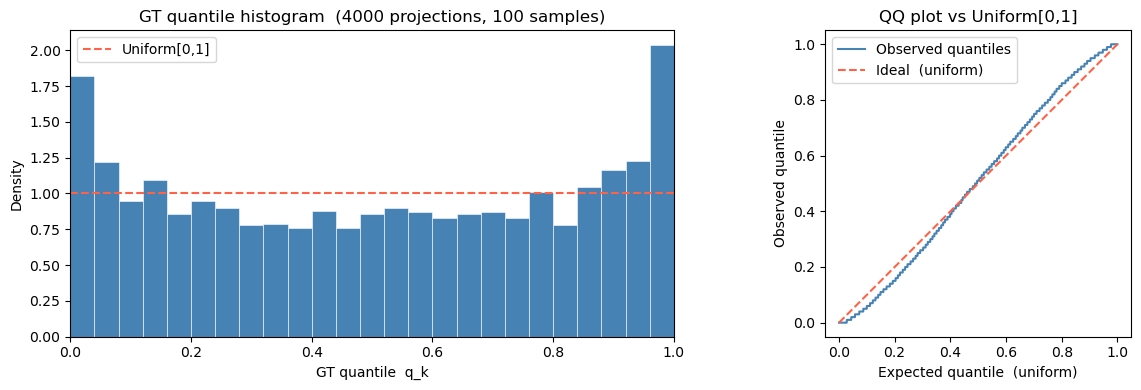

In [29]:

# ── Parameters ───────────────────────────────────────────────────────────────
N_PROJ_EVAL   = 4000   # number of random projection directions
N_SAMP_EVAL   = 100   # number of binary samples per projection
PROJ_RNG_SEED = 0

# ── Run evaluate_projections ──────────────────────────────────────────────────
proj_result = evaluate_projections(
    pred_lambda,
    gt_support,
    n_samples     = N_SAMP_EVAL,
    n_projections = N_PROJ_EVAL,
    sampling_fn   = ACTIVE_SAMPLING_FN,
    rng           = np.random.default_rng(PROJ_RNG_SEED),
)
q = proj_result["quantiles"]   # (P,) – one quantile per projection

# ── Summary stats ─────────────────────────────────────────────────────────────
print(f"n_projections : {N_PROJ_EVAL}")
print(f"n_samples     : {N_SAMP_EVAL}")
print(f"mean quantile : {q.mean():.4f}  (ideal ≈ 0.50)")
print(f"std           : {q.std():.4f}  (ideal ≈ 0.289)")
print(f"frac [.05,.95]: {((q >= 0.05) & (q <= 0.95)).mean():.3f}  (ideal ≈ 0.90)")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig_mq, axes_mq = plt.subplots(1, 2, figsize=(13, 4))

# Left – histogram of quantiles vs Uniform[0,1]
axes_mq[0].hist(q, bins=25, range=(0, 1), color="steelblue", edgecolor="white",
                linewidth=0.4, density=True)
axes_mq[0].axhline(1.0, color="tomato", linewidth=1.5, linestyle="--",
                   label="Uniform[0,1]")
axes_mq[0].set_xlabel("GT quantile  q_k")
axes_mq[0].set_ylabel("Density")
axes_mq[0].set_title(f"GT quantile histogram  ({N_PROJ_EVAL} projections, {N_SAMP_EVAL} samples)")
axes_mq[0].set_xlim(0, 1)
axes_mq[0].legend()

# Right – sorted quantile plot (QQ vs Uniform)
sorted_q = np.sort(q)
uniform  = np.linspace(0, 1, N_PROJ_EVAL)
axes_mq[1].plot(uniform, sorted_q, color="steelblue", linewidth=1.5,
                label="Observed quantiles")
axes_mq[1].plot([0, 1], [0, 1], color="tomato", linewidth=1.5,
                linestyle="--", label="Ideal  (uniform)")
axes_mq[1].set_xlabel("Expected quantile  (uniform)")
axes_mq[1].set_ylabel("Observed quantile")
axes_mq[1].set_title("QQ plot vs Uniform[0,1]")
axes_mq[1].set_aspect("equal")
axes_mq[1].legend()

plt.tight_layout()
plt.show()


Real GT  point count : 233
Fake GT  point count : 233
Overlap (pixels)     : 0


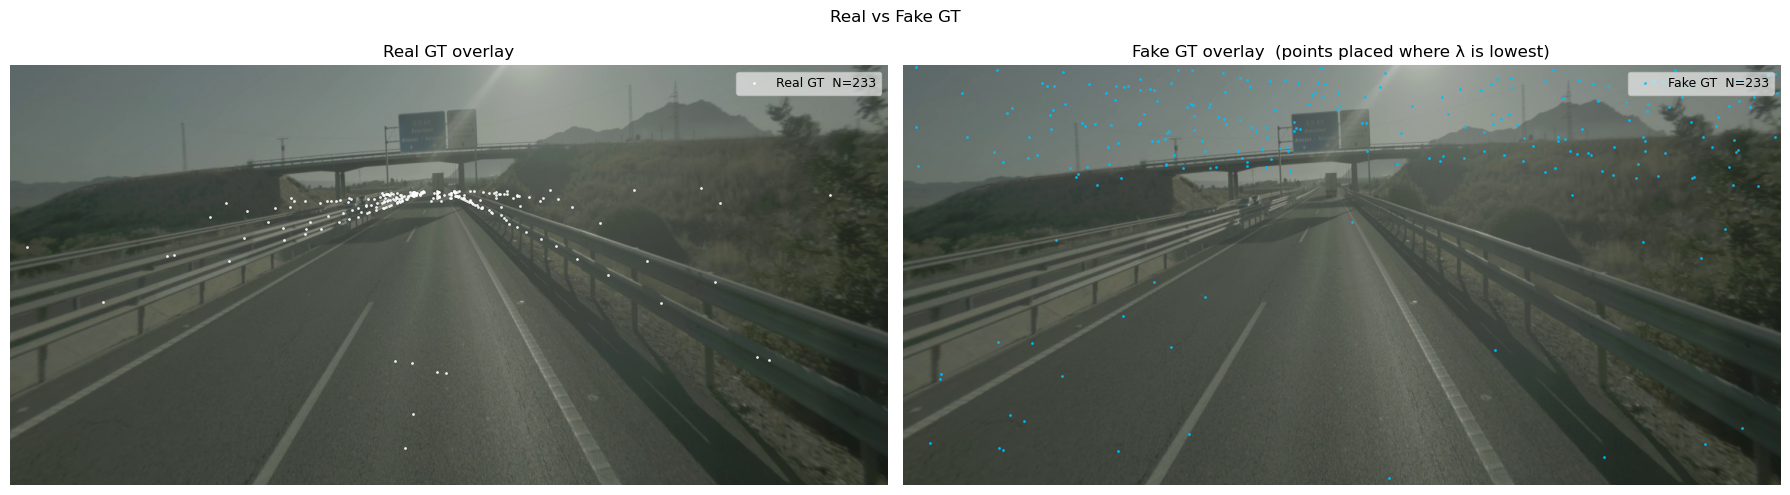

  Active pixels: 14,103 / 974,848  (1.45% of full space)

Fake GT quantile statistics:
  mean  = 0.4974  (ideal ≈ 0.50)
  std   = 0.3217  (ideal ≈ 0.289)
  frac [.05,.95] = 0.828  (ideal ≈ 0.90)


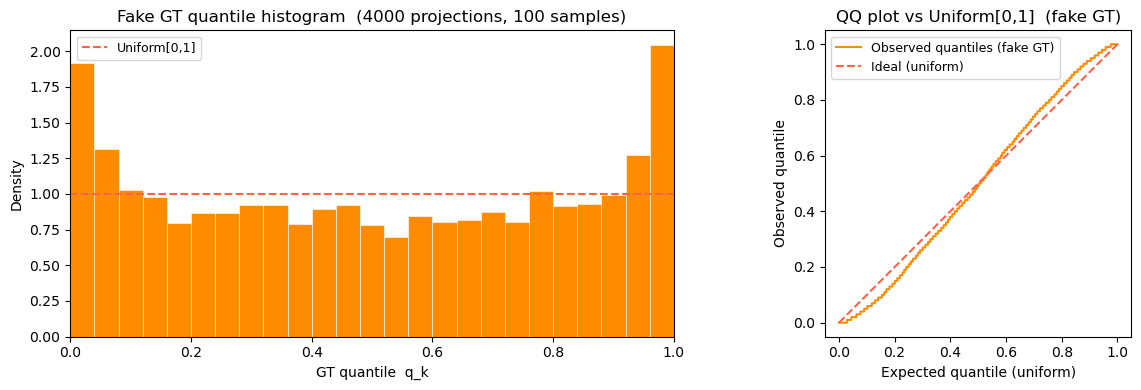

In [30]:

# ── Build a "very off" fake GT ────────────────────────────────────────────────
# Strategy: place the same number of points as the real GT, but sample their
# pixel locations from the *inverse* intensity (1 / (lambda + eps)).
# This puts points where the model expects almost nothing.

_fake_rng   = np.random.default_rng(42)
_n_fake     = int(gt_support.sum())          # same count as real GT
_eps        = 1e-6

# Inverted probability: high weight where pred_lambda is LOW
_inv_lam    = 1.0 / (pred_lambda.astype(np.float64) + _eps)
_inv_prob   = _inv_lam.ravel() / _inv_lam.sum()

# Draw pixel indices with replacement, then build binary grid
_fake_idx   = _fake_rng.choice(D, size=_n_fake, replace=False, p=_inv_prob)
fake_gt     = np.zeros(D, dtype=np.float64)
fake_gt[_fake_idx] = 1.0
fake_gt     = fake_gt.reshape(H, W)

print(f"Real GT  point count : {int(gt_support.sum())}")
print(f"Fake GT  point count : {int(fake_gt.sum())}")
print(f"Overlap (pixels)     : {int((fake_gt * (gt_support > 0)).sum())}")

# ── Display: image + fake GT overlay ─────────────────────────────────────────
_fys, _fxs = np.where(fake_gt > 0)

fig_fake, axes_fake = plt.subplots(1, 2, figsize=(18, 5))

axes_fake[0].imshow(img, aspect="auto")
_gys, _gxs = np.where(gt_support > 0)
axes_fake[0].scatter(_gxs, _gys, s=GT_DOT_SIZE, c="white", linewidths=0,
                     alpha=0.9, label=f"Real GT  N={int(gt_support.sum())}")
axes_fake[0].legend(loc="upper right", fontsize=9, framealpha=0.6)
axes_fake[0].axis("off")
axes_fake[0].set_title("Real GT overlay")

axes_fake[1].imshow(img, aspect="auto")
axes_fake[1].scatter(_fxs, _fys, s=GT_DOT_SIZE, c="deepskyblue", linewidths=0,
                     alpha=0.9, label=f"Fake GT  N={int(fake_gt.sum())}")
axes_fake[1].legend(loc="upper right", fontsize=9, framealpha=0.6)
axes_fake[1].axis("off")
axes_fake[1].set_title("Fake GT overlay  (points placed where λ is lowest)")

plt.suptitle("Real vs Fake GT", fontsize=12)
plt.tight_layout()
plt.show()

# ── Projection analysis with fake GT ─────────────────────────────────────────
proj_fake = evaluate_projections(
    pred_lambda,
    fake_gt,
    n_samples     = N_SAMP_EVAL,
    n_projections = N_PROJ_EVAL,
    sampling_fn   = ACTIVE_SAMPLING_FN,
    rng           = np.random.default_rng(PROJ_RNG_SEED),
)
q_fake = proj_fake["quantiles"]

print(f"\nFake GT quantile statistics:")
print(f"  mean  = {q_fake.mean():.4f}  (ideal ≈ 0.50)")
print(f"  std   = {q_fake.std():.4f}  (ideal ≈ 0.289)")
print(f"  frac [.05,.95] = {((q_fake >= 0.05) & (q_fake <= 0.95)).mean():.3f}  (ideal ≈ 0.90)")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig_fq, axes_fq = plt.subplots(1, 2, figsize=(13, 4))

axes_fq[0].hist(q_fake, bins=25, range=(0, 1), color="darkorange",
                edgecolor="white", linewidth=0.4, density=True)
axes_fq[0].axhline(1.0, color="tomato", linewidth=1.5, linestyle="--",
                   label="Uniform[0,1]")
axes_fq[0].set_xlabel("GT quantile  q_k")
axes_fq[0].set_ylabel("Density")
axes_fq[0].set_title(f"Fake GT quantile histogram  ({N_PROJ_EVAL} projections, {N_SAMP_EVAL} samples)")
axes_fq[0].set_xlim(0, 1)
axes_fq[0].legend(fontsize=9)

sorted_qf = np.sort(q_fake)
uniform   = np.linspace(0, 1, N_PROJ_EVAL)
axes_fq[1].plot(uniform, sorted_qf, color="darkorange", linewidth=1.5,
                label="Observed quantiles (fake GT)")
axes_fq[1].plot([0, 1], [0, 1], color="tomato", linewidth=1.5,
                linestyle="--", label="Ideal (uniform)")
axes_fq[1].set_xlabel("Expected quantile (uniform)")
axes_fq[1].set_ylabel("Observed quantile")
axes_fq[1].set_title("QQ plot vs Uniform[0,1]  (fake GT)")
axes_fq[1].set_aspect("equal")
axes_fq[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


Real GT  point count : 233
Sampled GT point count : 144  (E[N]=159.55,  N_prop=21601)
Overlap (pixels)     : 1


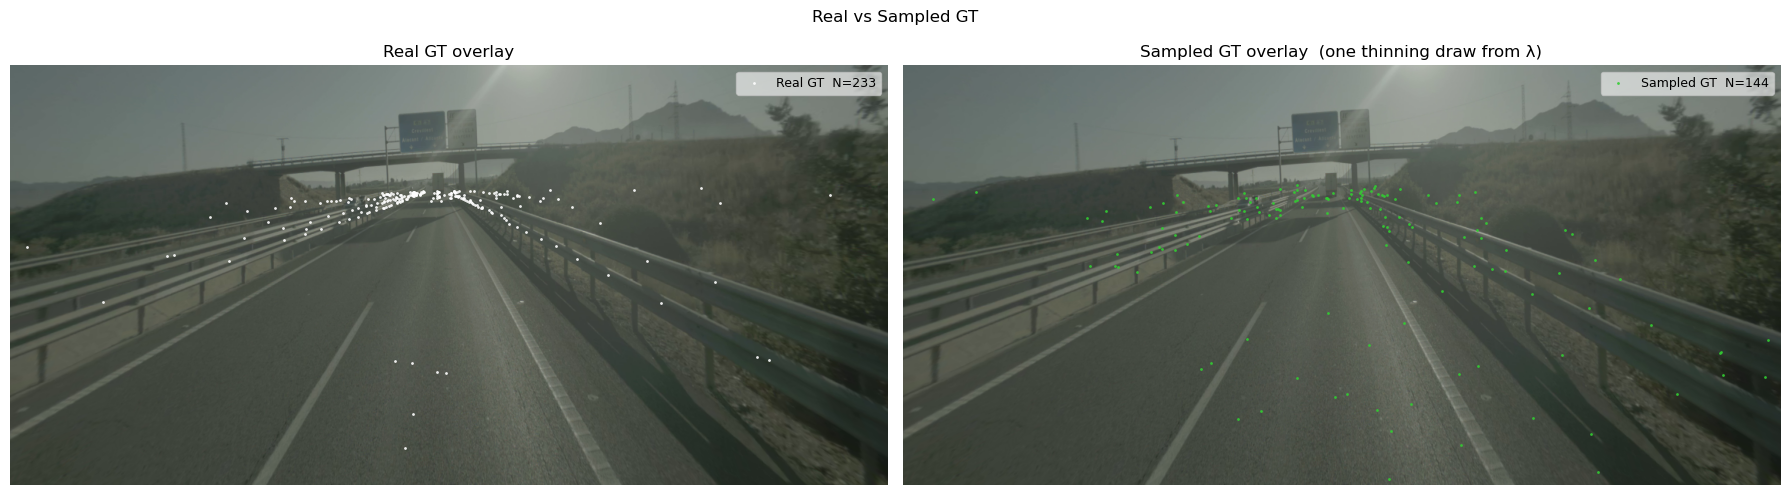

  Active pixels: 13,987 / 974,848  (1.43% of full space)

Sampled GT quantile statistics:
  mean  = 0.5010  (ideal ≈ 0.50)
  std   = 0.2844  (ideal ≈ 0.289)
  frac [.05,.95] = 0.915  (ideal ≈ 0.90)


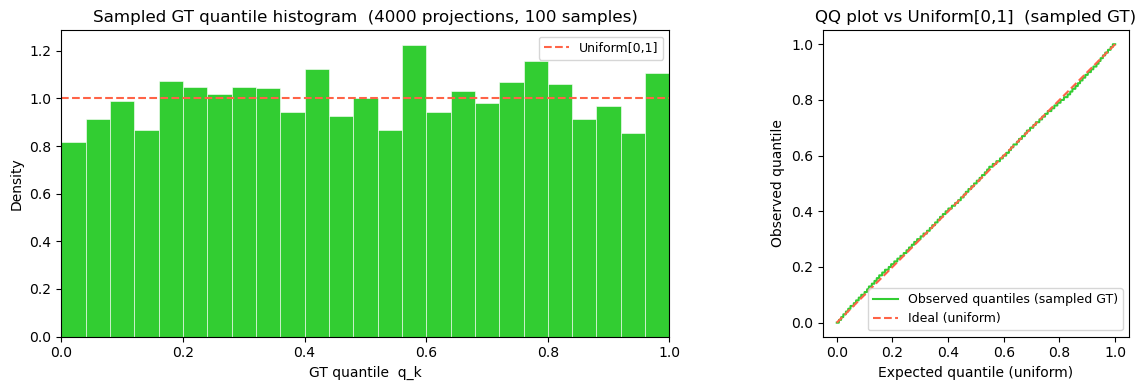

In [31]:

# ── Build a "sampled GT" – one draw from the predicted heatmap ────────────────
# Strategy: draw a single realisation of the PPP via thinning.
# This is what a perfectly calibrated model should produce – a sample that is
# statistically indistinguishable from the real GT under the model.

_samp_rng = np.random.default_rng(99)
_samp_pts, _samp_N, _samp_lam_max, _samp_N_prop = sample_ppp_by_thinning(
    pred_lambda, rng=_samp_rng
)
sampled_gt = points_to_binary_grid(_samp_pts, H, W)

print(f"Real GT  point count : {int(gt_support.sum())}")
print(f"Sampled GT point count : {int(sampled_gt.sum())}  "
      f"(E[N]={ppp['expected_count']:.2f},  N_prop={_samp_N_prop})")
print(f"Overlap (pixels)     : {int((sampled_gt * (gt_support > 0)).sum())}")

# ── Display: image + sampled GT overlay ───────────────────────────────────────
_sys, _sxs = np.where(sampled_gt > 0)
_gys2, _gxs2 = np.where(gt_support > 0)

fig_samp, axes_samp = plt.subplots(1, 2, figsize=(18, 5))

axes_samp[0].imshow(img, aspect="auto")
axes_samp[0].scatter(_gxs2, _gys2, s=GT_DOT_SIZE, c="white", linewidths=0,
                     alpha=0.9, label=f"Real GT  N={int(gt_support.sum())}")
axes_samp[0].legend(loc="upper right", fontsize=9, framealpha=0.6)
axes_samp[0].axis("off")
axes_samp[0].set_title("Real GT overlay")

axes_samp[1].imshow(img, aspect="auto")
axes_samp[1].scatter(_sxs, _sys, s=GT_DOT_SIZE, c="limegreen", linewidths=0,
                     alpha=0.9, label=f"Sampled GT  N={int(sampled_gt.sum())}")
axes_samp[1].legend(loc="upper right", fontsize=9, framealpha=0.6)
axes_samp[1].axis("off")
axes_samp[1].set_title("Sampled GT overlay  (one thinning draw from λ)")

plt.suptitle("Real vs Sampled GT", fontsize=12)
plt.tight_layout()
plt.show()

# ── Projection analysis with sampled GT ──────────────────────────────────────
proj_sampled = evaluate_projections(
    pred_lambda,
    sampled_gt,
    n_samples     = N_SAMP_EVAL,
    n_projections = N_PROJ_EVAL,
    sampling_fn   = ACTIVE_SAMPLING_FN,
    rng           = np.random.default_rng(PROJ_RNG_SEED),
)
q_sampled = proj_sampled["quantiles"]

print(f"\nSampled GT quantile statistics:")
print(f"  mean  = {q_sampled.mean():.4f}  (ideal ≈ 0.50)")
print(f"  std   = {q_sampled.std():.4f}  (ideal ≈ 0.289)")
print(f"  frac [.05,.95] = {((q_sampled >= 0.05) & (q_sampled <= 0.95)).mean():.3f}  (ideal ≈ 0.90)")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig_sq, axes_sq = plt.subplots(1, 2, figsize=(13, 4))

axes_sq[0].hist(q_sampled, bins=25, range=(0, 1), color="limegreen",
                edgecolor="white", linewidth=0.4, density=True)
axes_sq[0].axhline(1.0, color="tomato", linewidth=1.5, linestyle="--",
                   label="Uniform[0,1]")
axes_sq[0].set_xlabel("GT quantile  q_k")
axes_sq[0].set_ylabel("Density")
axes_sq[0].set_title(f"Sampled GT quantile histogram  ({N_PROJ_EVAL} projections, {N_SAMP_EVAL} samples)")
axes_sq[0].set_xlim(0, 1)
axes_sq[0].legend(fontsize=9)

sorted_qs = np.sort(q_sampled)
uniform_s = np.linspace(0, 1, N_PROJ_EVAL)
axes_sq[1].plot(uniform_s, sorted_qs, color="limegreen", linewidth=1.5,
                label="Observed quantiles (sampled GT)")
axes_sq[1].plot([0, 1], [0, 1], color="tomato", linewidth=1.5,
                linestyle="--", label="Ideal (uniform)")
axes_sq[1].set_xlabel("Expected quantile (uniform)")
axes_sq[1].set_ylabel("Observed quantile")
axes_sq[1].set_title("QQ plot vs Uniform[0,1]  (sampled GT)")
axes_sq[1].set_aspect("equal")
axes_sq[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


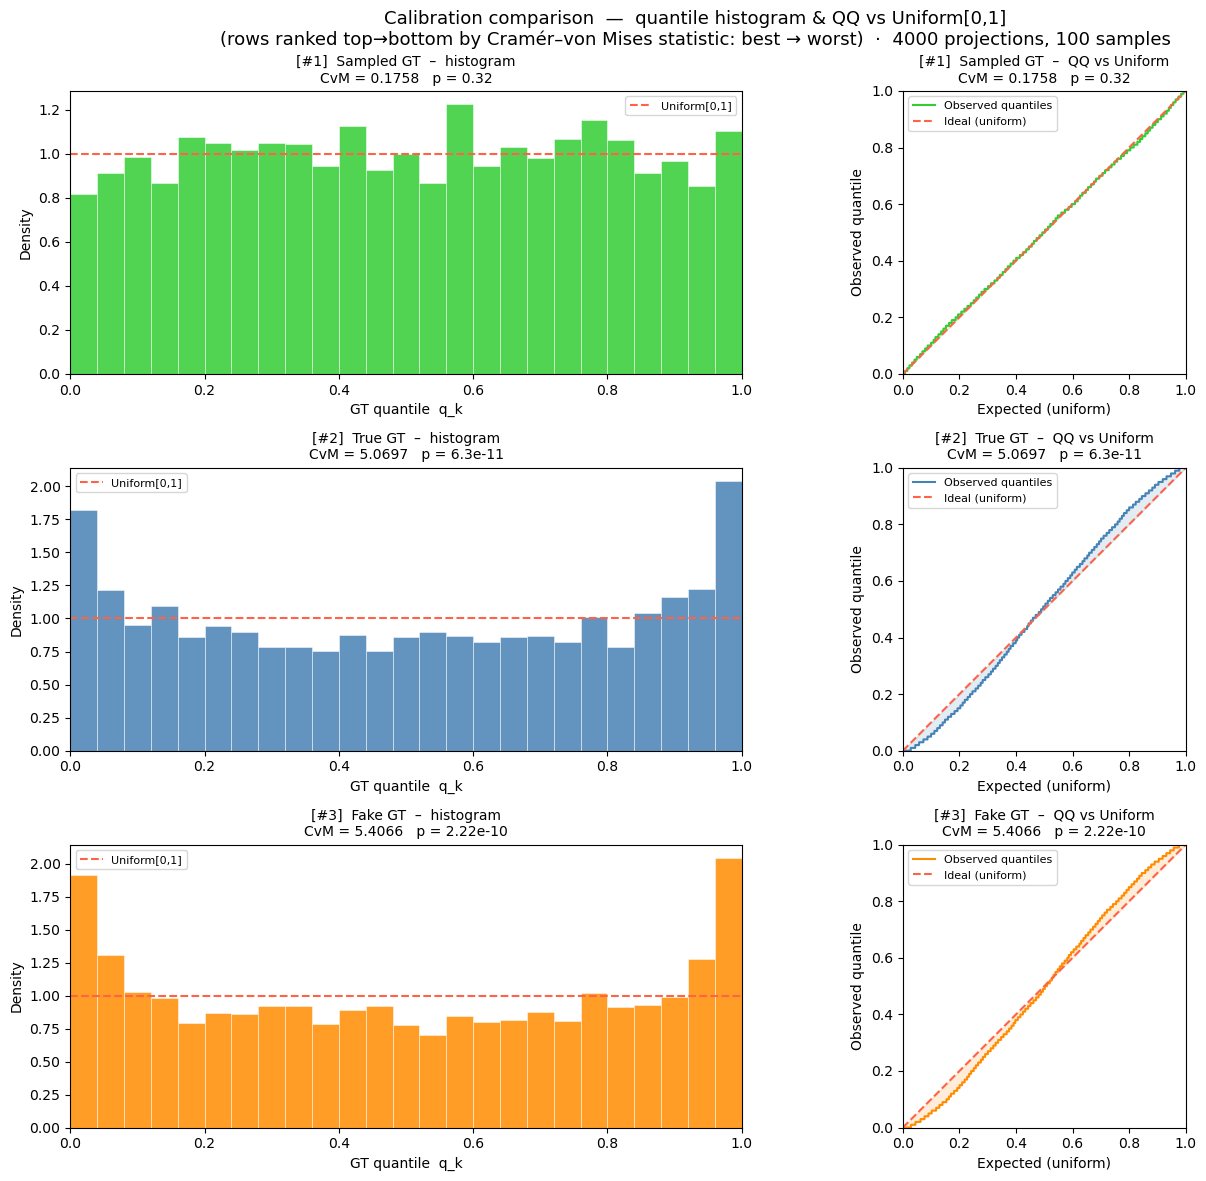


── Cramér–von Mises ranking  (↑ uniform  =  ↓ CvM statistic) ──
Rank   Label              CvM stat      p-value   verdict
──────────────────────────────────────────────────────────
  1    Sampled GT         0.17583       0.3197   ✓ consistent with Uniform
  2    True GT            5.06967    6.295e-11   ✗ NOT uniform
  3    Fake GT            5.40657     2.22e-10   ✗ NOT uniform


In [32]:

from scipy.stats import cramervonmises

# ── Three cases ───────────────────────────────────────────────────────────────
_cases = [
    ("True GT",    q,         "steelblue"),
    ("Fake GT",    q_fake,    "darkorange"),
    ("Sampled GT", q_sampled, "limegreen"),
]

# ── Cramér–von Mises against Uniform[0,1] ────────────────────────────────────
_cvm = []
for label, q_vals, color in _cases:
    res = cramervonmises(q_vals, "uniform")
    _cvm.append((label, color, q_vals, res.statistic, res.pvalue))

_cvm.sort(key=lambda x: x[3])   # ascending CvM = closest to uniform first

# ── Combined 3×2 figure ───────────────────────────────────────────────────────
_u = np.linspace(0, 1, N_PROJ_EVAL)

fig_cvm, axes_cvm = plt.subplots(3, 2, figsize=(14, 12))
fig_cvm.suptitle(
    "Calibration comparison  —  quantile histogram & QQ vs Uniform[0,1]\n"
    f"(rows ranked top→bottom by Cramér–von Mises statistic: best → worst)"
    f"  ·  {N_PROJ_EVAL} projections, {N_SAMP_EVAL} samples",
    fontsize=13,
)

for row, (label, color, q_vals, cvm_stat, cvm_p) in enumerate(_cvm):
    ax_h = axes_cvm[row, 0]
    ax_q = axes_cvm[row, 1]
    tag  = f"CvM = {cvm_stat:.4f}   p = {cvm_p:.3g}"

    # ── quantile histogram ────────────────────────────────────────────────────
    ax_h.hist(q_vals, bins=25, range=(0, 1), color=color,
              edgecolor="white", linewidth=0.4, density=True, alpha=0.85)
    ax_h.axhline(1.0, color="tomato", linewidth=1.5, linestyle="--",
                 label="Uniform[0,1]")
    ax_h.set_xlabel("GT quantile  q_k")
    ax_h.set_ylabel("Density")
    ax_h.set_title(f"[#{row+1}]  {label}  –  histogram\n{tag}", fontsize=10)
    ax_h.set_xlim(0, 1)
    ax_h.legend(fontsize=8)

    # ── QQ vs Uniform ─────────────────────────────────────────────────────────
    sq = np.sort(q_vals)
    ax_q.plot(_u, sq, color=color, linewidth=1.5, label="Observed quantiles")
    ax_q.plot([0, 1], [0, 1], color="tomato", linewidth=1.5,
              linestyle="--", label="Ideal (uniform)")
    ax_q.fill_between(_u, _u, sq, alpha=0.15, color=color)
    ax_q.set_xlabel("Expected (uniform)")
    ax_q.set_ylabel("Observed quantile")
    ax_q.set_title(f"[#{row+1}]  {label}  –  QQ vs Uniform\n{tag}", fontsize=10)
    ax_q.set_xlim(0, 1); ax_q.set_ylim(0, 1)
    ax_q.set_aspect("equal")
    ax_q.legend(fontsize=8)

plt.tight_layout()
plt.show()

# ── Ranking table ─────────────────────────────────────────────────────────────
print("\n── Cramér–von Mises ranking  (↑ uniform  =  ↓ CvM statistic) ──")
print(f"{'Rank':<6} {'Label':<14} {'CvM stat':>12} {'p-value':>12}   verdict")
print("─" * 58)
for rank, (label, color, q_vals, cvm_stat, cvm_p) in enumerate(_cvm, 1):
    verdict = "✓ consistent with Uniform" if cvm_p > 0.05 else "✗ NOT uniform"
    print(f"  {rank}    {label:<14}  {cvm_stat:>10.5f}   {cvm_p:>10.4g}   {verdict}")



────────────────────────────────────────────────────────────
Model : test_gen_data_meric_13600264  (10 images)
  Active pixels: 10,389 / 974,848  (1.07% of full space)
  [  1/10]  sample_000000  CvM=2.07901
  Active pixels: 16,427 / 974,848  (1.69% of full space)
  [  2/10]  sample_000001  CvM=1.12760
  Active pixels: 12,862 / 974,848  (1.32% of full space)
  [  3/10]  sample_000002  CvM=2.19440
  Active pixels: 15,298 / 974,848  (1.57% of full space)
  [  4/10]  sample_000003  CvM=0.49554
  Active pixels: 14,168 / 974,848  (1.45% of full space)
  [  5/10]  sample_000004  CvM=1.74652
  Active pixels: 14,774 / 974,848  (1.52% of full space)
  [  6/10]  sample_000005  CvM=0.22892
  Active pixels: 11,108 / 974,848  (1.14% of full space)
  [  7/10]  sample_000006  CvM=0.78723
  Active pixels: 17,399 / 974,848  (1.78% of full space)
  [  8/10]  sample_000007  CvM=6.63516
  Active pixels: 14,430 / 974,848  (1.48% of full space)
  [  9/10]  sample_000008  CvM=1.59518
  Active pixels: 14,345 

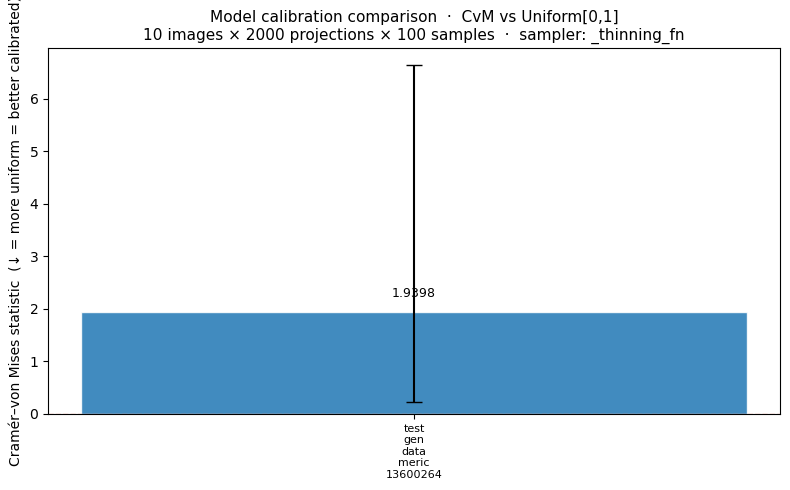

In [33]:

from scipy.stats import cramervonmises

# ── Parameters ────────────────────────────────────────────────────────────────
N_IMAGES_EVAL = 10    # number of samples per model  (set to None for all)
N_PROJ_MULTI  = 2000  # projection directions per sample
N_SAMP_MULTI  = 100   # samples drawn from lambda per projection evaluation
RNG_SEED_MULTI = 0

# ── Per-model CvM sweep ───────────────────────────────────────────────────────
model_results = {}   # model_name -> list of CvM statistics (one per image)

for model_name, h5_dir in H5_DIRS.items():
    if not os.path.isdir(h5_dir):
        print(f"[SKIP] {model_name}  – directory not found")
        continue

    _h5_files = sorted(glob.glob(os.path.join(h5_dir, "rank*.h5")))
    _samples  = list_h5_samples(_h5_files)

    if N_IMAGES_EVAL is not None:
        _samples = _samples[:N_IMAGES_EVAL]

    print(f"\n{'─'*60}")
    print(f"Model : {model_name}  ({len(_samples)} images)")

    cvm_stats = []
    for idx, (h5_path, sample_key) in enumerate(_samples):
        s = load_h5_sample(h5_path, sample_key)
        _pl = s["pred_lambda"]
        _gt = s["gt_support"]

        _res = evaluate_projections(
            _pl, _gt,
            n_samples     = N_SAMP_MULTI,
            n_projections = N_PROJ_MULTI,
            sampling_fn   = ACTIVE_SAMPLING_FN,
            rng           = np.random.default_rng(RNG_SEED_MULTI + idx),
        )
        cvm = cramervonmises(_res["quantiles"], "uniform").statistic
        cvm_stats.append(cvm)
        print(f"  [{idx+1:>3}/{len(_samples)}]  {sample_key}  CvM={cvm:.5f}")

    model_results[model_name] = np.array(cvm_stats)

# ── Summary table ─────────────────────────────────────────────────────────────
print(f"\n{'═'*72}")
print(f"{'Model':<52} {'mean':>8} {'min':>8} {'max':>8}  rank")
print(f"{'─'*72}")

_ranked = sorted(model_results.items(), key=lambda kv: kv[1].mean())
for rank, (name, stats) in enumerate(_ranked, 1):
    short = name if len(name) <= 50 else "…" + name[-49:]
    print(f"  {rank}  {short:<50}  {stats.mean():>7.5f}  {stats.min():>7.5f}  {stats.max():>7.5f}")

# ── Bar chart comparison ───────────────────────────────────────────────────────
_names  = [kv[0] for kv in _ranked]
_means  = [kv[1].mean() for kv in _ranked]
_mins   = [kv[1].mean() - kv[1].min() for kv in _ranked]   # lower error
_maxes  = [kv[1].max() - kv[1].mean() for kv in _ranked]   # upper error
_colors = plt.cm.tab10.colors

fig_comp, ax_comp = plt.subplots(figsize=(max(8, len(_names) * 2.5), 5))
bars = ax_comp.bar(range(len(_names)), _means, color=_colors[:len(_names)],
                   edgecolor="white", alpha=0.85)
ax_comp.errorbar(range(len(_names)), _means,
                 yerr=[_mins, _maxes],
                 fmt="none", color="black", capsize=6, linewidth=1.5)
ax_comp.set_xticks(range(len(_names)))
ax_comp.set_xticklabels([n.replace("_", "\n") for n in _names], fontsize=8)
ax_comp.set_ylabel("Cramér–von Mises statistic  (↓ = more uniform = better calibrated)")
ax_comp.set_title(
    f"Model calibration comparison  ·  CvM vs Uniform[0,1]\n"
    f"{N_IMAGES_EVAL or 'all'} images × {N_PROJ_MULTI} projections × {N_SAMP_MULTI} samples  "
    f"·  sampler: {ACTIVE_SAMPLING_FN.__name__}",
    fontsize=11,
)
ax_comp.axhline(0, color="tomato", linewidth=1, linestyle="--", alpha=0.5)
for bar, mean in zip(bars, _means):
    ax_comp.text(bar.get_x() + bar.get_width() / 2, mean + max(_maxes) * 0.05,
                 f"{mean:.4f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()
